cuda


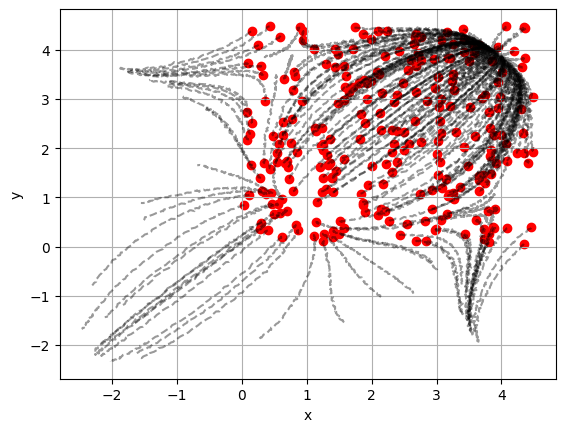

Training Neural ODE ...


/tmp/ipykernel_130270/1500101581.py:136: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)



Epoch 10

Equilibrium 1
x_equilibrium      = [ 0.17788395 -0.1535988 ]
x_true_equilibrium = [0.7853982 0.7853982]
||x_eq - x_true||  = 1.1183867454528809
residual ||f(x)||  = 7.44963642773655e-07
eigenvalues        = [0.85144174+0.j 0.37105155+0.j]

Equilibrium 2
x_equilibrium      = [ 0.17753844 -0.1531312 ]
x_true_equilibrium = [0.7853982 3.9269907]
||x_eq - x_true||  = 4.125153064727783
residual ||f(x)||  = 0.00021883161389268935
eigenvalues        = [0.8514571 +0.j 0.37105834+0.j]

Equilibrium 3
x_equilibrium      = [9.79488    0.64687836]
x_true_equilibrium = [3.9269907 0.7853982]
||x_eq - x_true||  = 5.869524002075195
residual ||f(x)||  = 1.0611921548843384
eigenvalues        = [-0.05220947+0.j  0.20652716+0.j]

Equilibrium 4
x_equilibrium      = [ 0.1745309  -0.14851603]
x_true_equilibrium = [3.9269907 3.9269907]
||x_eq - x_true||  = 5.539919376373291
residual ||f(x)||  = 0.0022659595124423504
eigenvalues        = [0.85160124+0.j 0.37112415+0.j]
[ADJ] Epoch 010 | train 0.675009

In [1]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda"
print(device)
class Cos(nn.Module):
   def __init__(self):
        super().__init__()

       

   def forward(self,t,z):
        x, y = z[...,0], z[...,1]
      
        dx = -2*(torch.cos(x)-torch.sin(x)) - (torch.cos(y)-torch.sin(y))
        dy = -2*(torch.cos(y)-torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)
   

def make_grid_dataset(T=3.0, step=60, noise_std=0.02,
                      nx=30, ny=30,
                      x_range=(0.0, 4.5), y_range=(0.0, 4.5)):
    gt = Cos().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    z0 = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

def make_random_dataset(n_traj=600, T=3.0, step=60, noise_std=0.02,
                        x_range=(0.0, 6.0), y_range=(0.0, 6.0)):
    gt = Cos().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    x0 = x_range[0] + (x_range[1] - x_range[0]) * torch.rand(n_traj, device=device)
    y0 = y_range[0] + (y_range[1] - y_range[0]) * torch.rand(n_traj, device=device)
    z0 = torch.stack([x0, y0], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

z0_train, t_eval, Z_train = make_grid_dataset(
    T=1.0,
    step=100,
    noise_std=0.01,
    nx=30,
    ny=30,
    x_range=(0.0, 4.5),
    y_range=(0.0, 4.5 )
)

z0_test, _, Z_test = make_random_dataset(
    n_traj=600,
    T=1.0,
    step=100,
    noise_std=0.01,
    x_range=(0.0, 4.5),
    y_range=(0.0, 4.5)
)

train_load = DataLoader(
    TensorDataset(z0_train, Z_train),
    batch_size=256,
    shuffle=True
)

test_load = DataLoader(
    TensorDataset(z0_test, Z_test),
    batch_size=256,
    shuffle=False
)


for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count
    
true_equilibria = torch.tensor([
    [math.pi/4,     math.pi/4],     # unstable
    [math.pi/4,     5*math.pi/4],   # saddle
    [5*math.pi/4,   math.pi/4],     # saddle
    [5*math.pi/4,   5*math.pi/4],   # stable
], dtype=torch.float32, device=device)
def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

def find_equilibrium(func, x0, t0=0.0, steps=300, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

def analyze_equilibrium(func, epoch, t0=0.0):
    print(f"\nEpoch {epoch}")
    eq_errors = []
    eigvals_all = []

    for i, x_true_eq in enumerate(true_equilibria, 1):
        x0 = x_true_eq + 0.2 * torch.randn_like(x_true_eq)

        x_eq, res = find_equilibrium(func, x0, t0=t0, steps=300, lr=0.02)
        err = torch.norm(x_eq - x_true_eq).item()
        eq_errors.append(err)
       

        J = jacobian_2d(func, x_eq, t0=t0)
        eigvals = torch.linalg.eigvals(J)
        eigvals_all.append(eigvals.detach().cpu())

        print(f"\nEquilibrium {i}")
        print("x_equilibrium      =", x_eq.detach().cpu().numpy())
        print("x_true_equilibrium =", x_true_eq.detach().cpu().numpy())
        print("||x_eq - x_true||  =", err)
        print("residual ||f(x)||  =", res)
        print("eigenvalues        =", eigvals.detach().cpu().numpy())

    return eq_errors,eigvals_all
        
def train(model, loader, t_eval, epochs=800, lr=1e-3, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    test_losses = []
    eq_errors_history = []
    eigvals_history = []
    epoch_marks = []

    for ep in range(1, epochs + 1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()

        tr = evaluate(model, train_load, t_eval)
        te = evaluate(model, test_load, t_eval)

        train_losses.append(tr)
        test_losses.append(te)

        if ep % 10 == 0:
            eq_errors, eigvals_all = analyze_equilibrium(model.func, epoch=ep, t0=0.0)
            eq_errors_history.append(eq_errors)
            eigvals_history.append(eigvals_all)
            epoch_marks.append(ep)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")

    return model, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks

func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("Training Neural ODE ...")
node_adj, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks = train(
    node_adj, train_load, t_eval, tag="ADJ"
)

print("\nFinal MSE")
print("Train:", evaluate(node_adj, train_load, t_eval))
print("Test :", evaluate(node_adj, test_load,  t_eval))


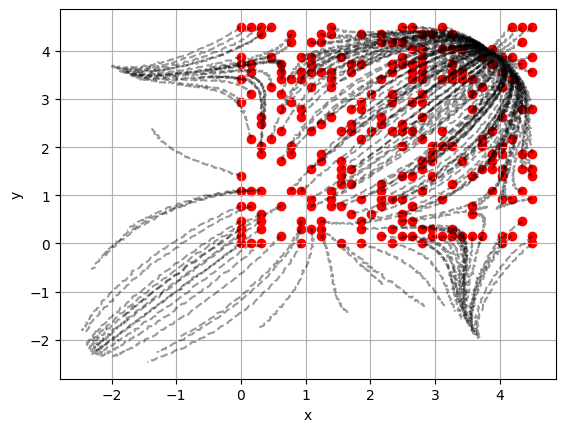

In [85]:
for z0_batch, Z_batch in train_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

In [9]:
torch.save({
    "z0_train": z0_train.cpu(),
    "Z_train": Z_train.cpu(),

    "z0_test": z0_test.cpu(),
    "Z_test": Z_test.cpu(),

    "t_eval": t_eval.cpu()
}, "dataset.pt")



In [3]:
eigvals_history_cpu = [
    [eig.cpu() for eig in snapshot]
    for snapshot in eigvals_history
]

torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),
    "train_losses": train_losses,
    "test_losses": test_losses,
    "eq_errors_history": eq_errors_history,
    "eigvals_history": eigvals_history_cpu,
    "epoch_marks": epoch_marks,
}, "node_adj.pth") 

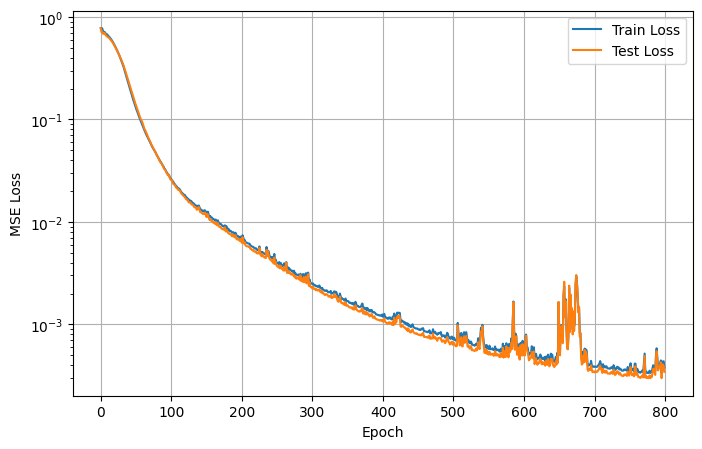

In [4]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()
plt.show()

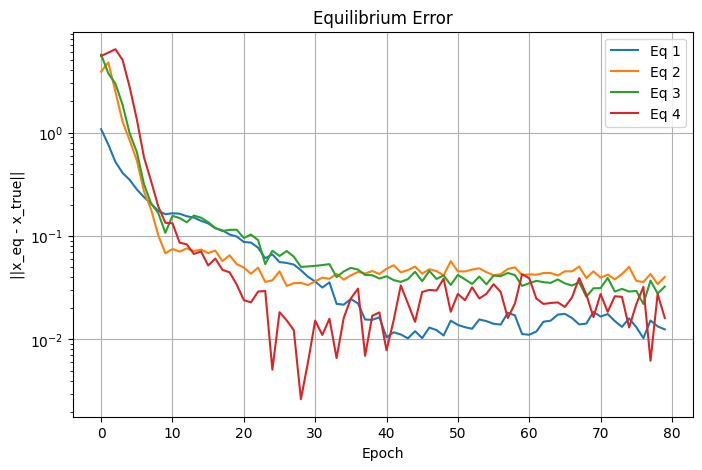

In [15]:
import numpy as np

eq_errors_history = np.array(eq_errors_history)  # shape (epochs, 4)

plt.figure(figsize=(8,5))

for i in range(eq_errors_history.shape[1]):
    plt.plot(eq_errors_history[:, i], label=f"Eq {i+1}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("||x_eq - x_true||")
plt.title("Equilibrium Error")
plt.legend()
plt.grid()

plt.show()

In [5]:
func = node_adj.func

In [6]:
import numpy as np
import math
import matplotlib.pyplot as plt

def reorder_eigs_by_continuity(eig_seq):
    
    eig_seq = np.array(eig_seq, dtype=np.complex128)
    out = np.zeros_like(eig_seq, dtype=np.complex128)

    out[0] = eig_seq[0]

    for i in range(1, len(eig_seq)):
        prev = out[i - 1]
        cur = eig_seq[i]

        cost_same = abs(cur[0] - prev[0]) + abs(cur[1] - prev[1])
        cost_swap = abs(cur[1] - prev[0]) + abs(cur[0] - prev[1])

        if cost_swap < cost_same:
            out[i] = [cur[1], cur[0]]
        else:
            out[i] = cur

    return out


def plot_eigs_simple(eigvals_history, epoch_marks):
    eigvals_history = np.array(eigvals_history, dtype=object)

    true_eigs = [
        [3 * math.sqrt(2),  1 * math.sqrt(2)],    # Eq 1: unstable
        [math.sqrt(6),     -math.sqrt(6)],        # Eq 2: saddle
        [math.sqrt(6),     -math.sqrt(6)],        # Eq 3: saddle
        [-1 * math.sqrt(2), -3 * math.sqrt(2)]    # Eq 4: stable
    ]

    for eq_idx in range(4):
        eig_seq = []

        for i in range(len(eigvals_history)):
            lam = eigvals_history[i][eq_idx]
            eig_seq.append([complex(lam[0]), complex(lam[1])])

        eig_seq = reorder_eigs_by_continuity(eig_seq)

        re1 = eig_seq[:, 0].real
        re2 = eig_seq[:, 1].real
        im1 = eig_seq[:, 0].imag
        im2 = eig_seq[:, 1].imag

        plt.figure(figsize=(8, 5))

        plt.plot(epoch_marks, re1, label="Re λ1")
        plt.plot(epoch_marks, re2, label="Re λ2")
        plt.plot(epoch_marks, im1, "--", label="Im λ1")
        plt.plot(epoch_marks, im2, "--", label="Im λ2")

        lam_true = true_eigs[eq_idx]

        plt.axhline(lam_true[0], color="red", linestyle="-", alpha=0.8, label="true Re")
        plt.axhline(lam_true[1], color="red", linestyle="-", alpha=0.8)

        plt.axhline(0, color="black", linestyle="--")

        plt.title(f"Equilibrium {eq_idx+1}")
        plt.xlabel("Epoch")
        plt.ylabel("Value")
        plt.legend()
        plt.grid(True)
        plt.show()

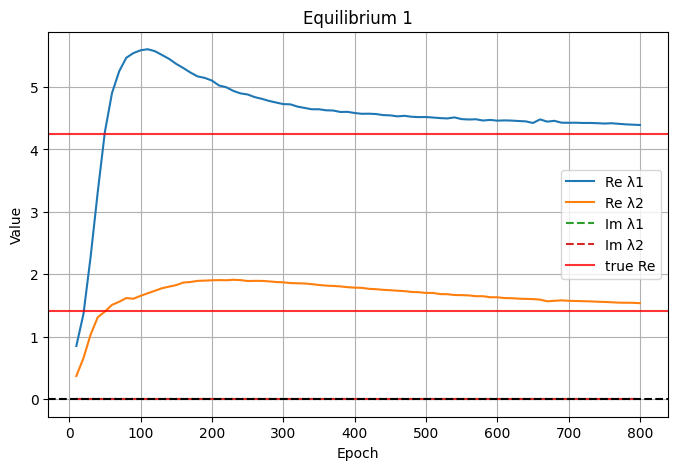

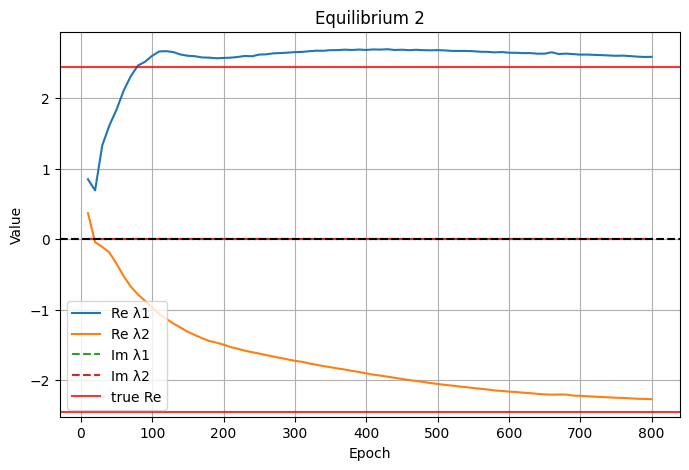

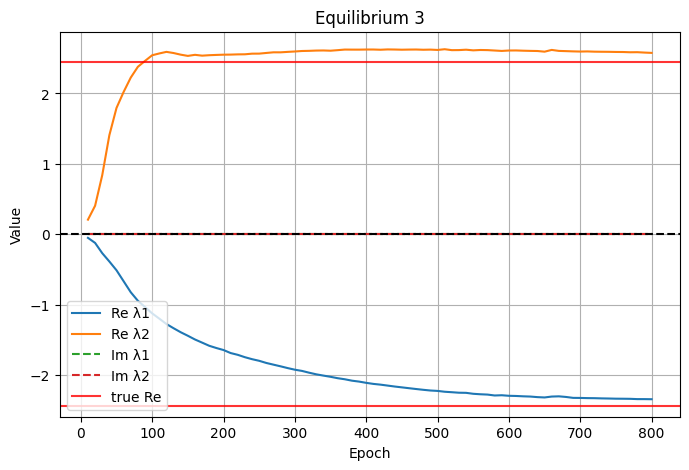

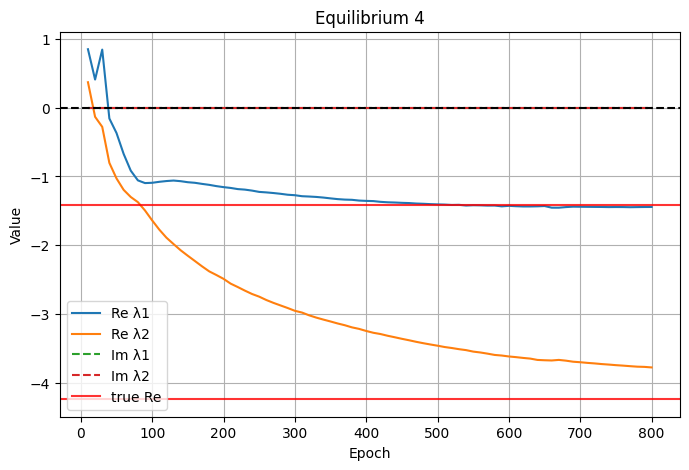

In [7]:
plot_eigs_simple(eigvals_history, epoch_marks)

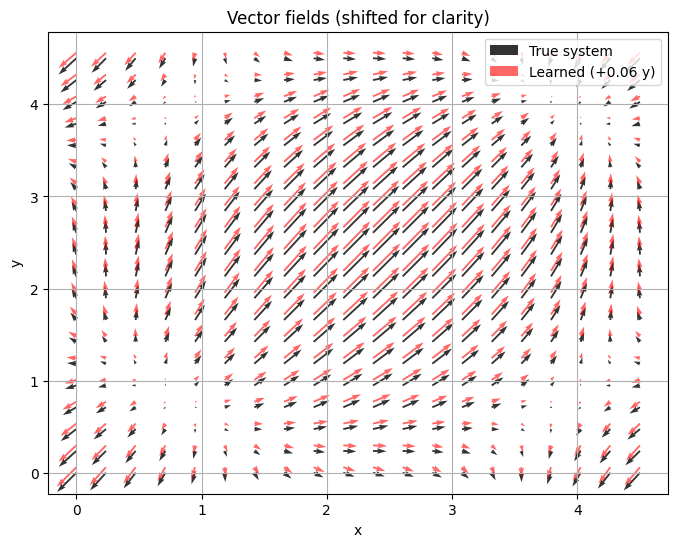

In [84]:
def plot_vector_fields_shifted(true_func, learned_func,
                              shift_y=0.6,
                              x_range=(0.0, 4.5), y_range=(0.0, 4.5),
                              nx=20, ny=20, t0=0.0, device="cpu"):

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    Z = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        V_true = true_func(torch.tensor(t0, device=device), Z).cpu().numpy()
        V_learn = learned_func(torch.tensor(t0, device=device), Z).cpu().numpy()

    Xn = Z[:, 0].cpu().numpy()
    Yn = Z[:, 1].cpu().numpy()

    plt.figure(figsize=(8, 6))

    plt.quiver(Xn, Yn,
               V_true[:, 0], V_true[:, 1],
               color='black', alpha=0.8, label='True system')

    plt.quiver(Xn, Yn + shift_y,
               V_learn[:, 0], V_learn[:, 1],
               color='red', alpha=0.6, label=f'Learned (+{shift_y} y)')

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Vector fields (shifted for clarity)")
    plt.grid()
    plt.legend()
    plt.show()

gt = Cos().to(device)
func = node_adj.func
plot_vector_fields_shifted(
    true_func=gt,
    learned_func=func,
    shift_y=0.06,
    device=device
)

In [ ]:


def plot_phase_portrait_system(gt_func, z0, t_eval, true_equilibria,
                               xlim=(0, 6), ylim=(0, 6),
                               grid_n=25, max_traj=80,
                               traj_alpha=0.35, arrow_step=12):
    plt.figure(figsize=(8, 8))


    xs = torch.linspace(xlim[0], xlim[1], grid_n, device=device)
    ys = torch.linspace(ylim[0], ylim[1], grid_n, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')
    XY = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        F = gt_func(torch.tensor(0.0, device=device), XY)
        U = F[:, 0].reshape(grid_n, grid_n).cpu().numpy()
        V = F[:, 1].reshape(grid_n, grid_n).cpu().numpy()

    plt.quiver(
        X.cpu().numpy(),
        Y.cpu().numpy(),
        U, V,
        color='gray',
        alpha=0.55
    )

    n = min(max_traj, z0.size(0))

    with torch.no_grad():
        Z_clean = odeint(
            gt_func,
            z0[:n].to(device),
            t_eval.to(device),
            method="dopri5"
        )
        Z_clean = Z_clean.transpose(0, 1).contiguous()   # [batch, time, 2]

    for i in range(n):
        x = Z_clean[i, :, 0].cpu().numpy()
        y = Z_clean[i, :, 1].cpu().numpy()

        
        plt.plot(x, y, 'k-', alpha=traj_alpha)

      
        for j in range(0, len(x) - 1, arrow_step):
            dx = x[j + 1] - x[j]
            dy = y[j + 1] - y[j]

            plt.arrow(
                x[j], y[j],
                dx, dy,
                shape='full',
                lw=0,
                length_includes_head=True,
                head_width=0.06,
                color='black',
                alpha=0.7
            )


    eq = true_equilibria.detach().cpu().numpy()
    plt.scatter(
        eq[:, 0],
        eq[:, 1],
        c='blue',
        s=180,
        marker='x',
        linewidths=3,
        label='equilibria'
    )

    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Phase portrait of the true system")
    plt.grid(True)
    plt.legend()
    plt.show()

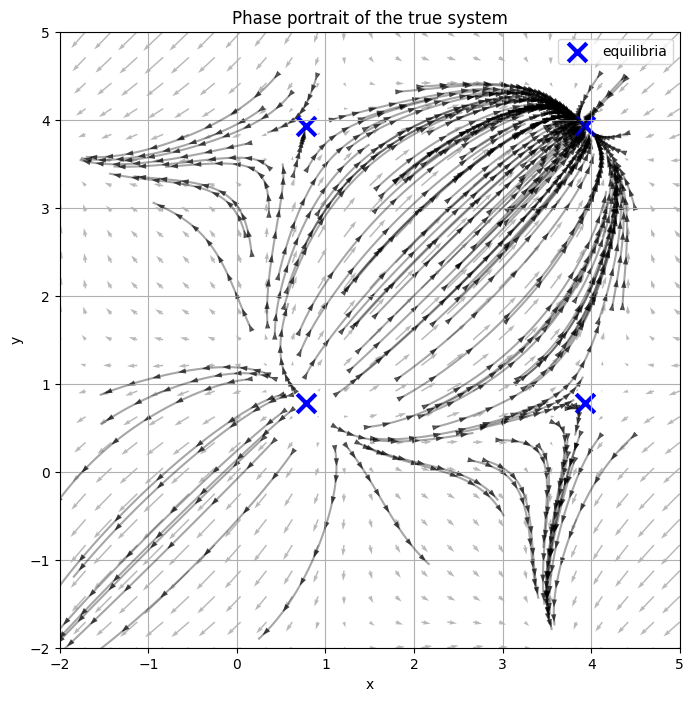

In [79]:
gt = Cos().to(device)

true_equilibria = torch.tensor([
    [math.pi/4,     math.pi/4],
    [math.pi/4,     5*math.pi/4],
    [5*math.pi/4,   math.pi/4],
    [5*math.pi/4,   5*math.pi/4],
], dtype=torch.float32, device=device)

plot_phase_portrait_system(
    gt_func=gt,
    z0=z0_test,          # или z0_train
    t_eval=t_eval,
    true_equilibria=true_equilibria,
    xlim=(-2, 5),
    ylim=(-2, 5),
    grid_n=25,
    max_traj=150,
    traj_alpha=0.35,
    arrow_step=12
)

In [51]:
def plot_time_series_comparison(model, loader, t_eval, num_samples):
    model.eval()

    with torch.no_grad():
        z0_batch, Z_true = next(iter(loader))
        z0_batch = z0_batch.to(device)
        Z_true = Z_true.to(device)

        Z_pred = model(z0_batch, t_eval)

    num_samples = min(num_samples, z0_batch.size(0))
    t_np = t_eval.detach().cpu().numpy()

    for i in range(num_samples):
        x_true = Z_true[i, :, 0].detach().cpu().numpy()
        y_true = Z_true[i, :, 1].detach().cpu().numpy()

        x_pred = Z_pred[i, :, 0].detach().cpu().numpy()
        y_pred = Z_pred[i, :, 1].detach().cpu().numpy()

        plt.figure(figsize=(9, 4))

        plt.plot(t_np, x_true, label='x true')
        plt.plot(t_np, x_pred, '--', label='x pred')
        plt.plot(t_np, y_true, label='y true')
        plt.plot(t_np, y_pred, '--', label='y pred')

        plt.title(f"Time series comparison (sample {i})")
        plt.xlabel("t")
        plt.ylabel("state")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

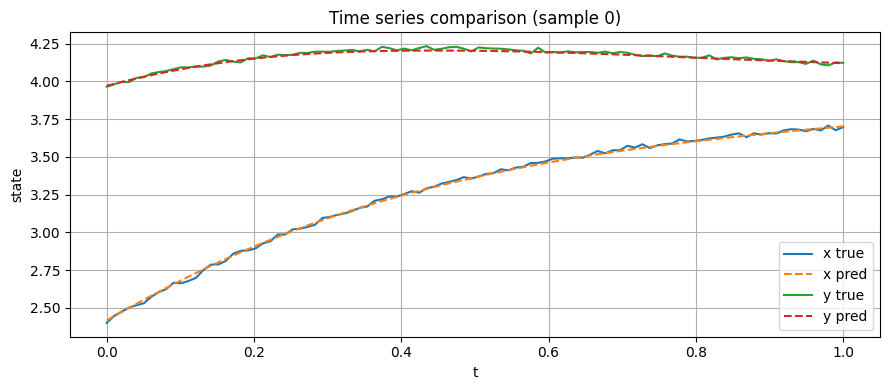

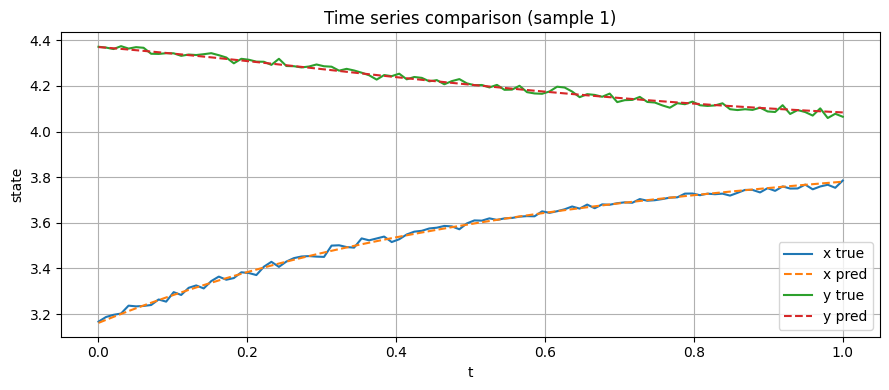

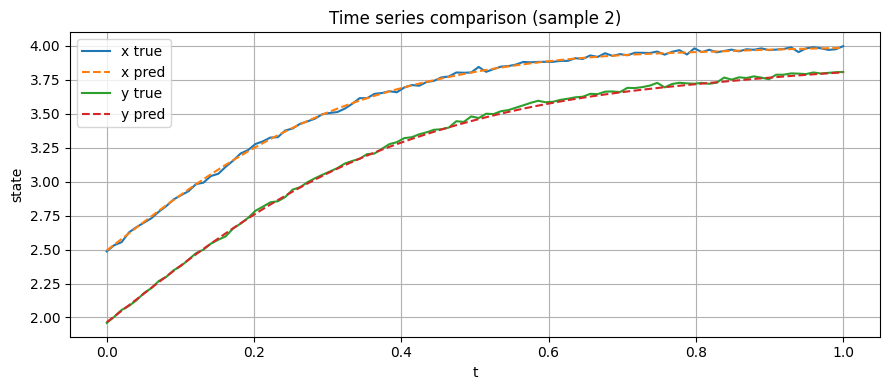

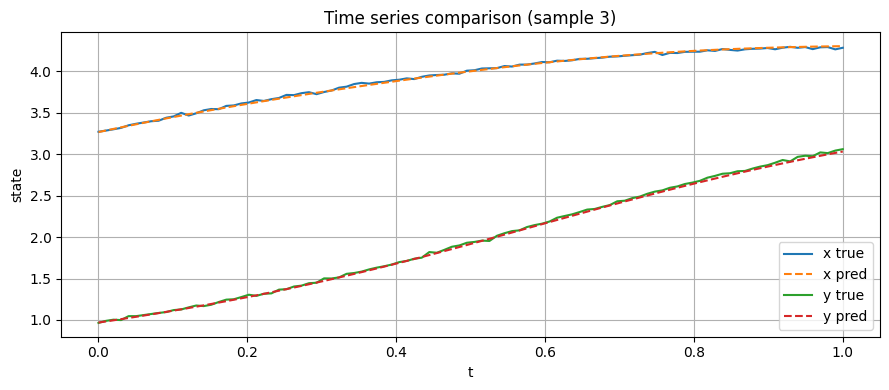

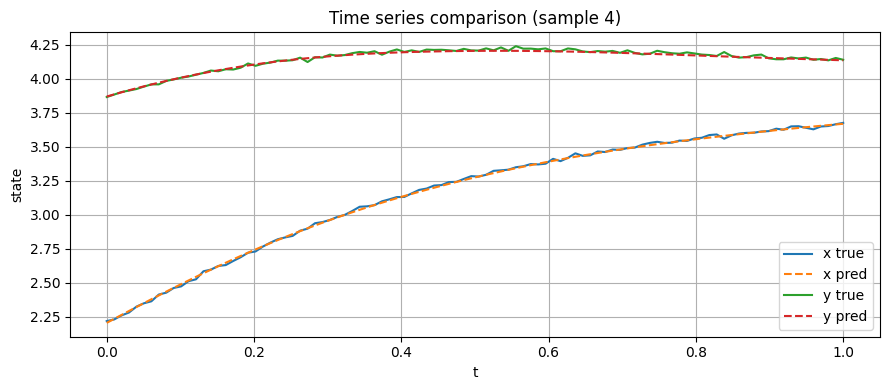

In [53]:
plot_time_series_comparison(node_adj, test_load, t_eval, num_samples=5)